# TASK 3 — DATA VISUALIZATION DASHBOARD
### Cricket Match & Toss Analysis

**Dataset:** `matches.csv` (636 rows, 18 columns)  


## 1. Import libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plts
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 14
print("Libraries imported successfully")

Libraries imported successfully


## 2. Load the dataset

In [6]:
CSV_FILE = "matches.csv"

if not Path(CSV_FILE).exists():
    raise FileNotFoundError(
        "matches.csv nahi mili. Is CSV file ko notebook ke same folder mein rakhein."
    )

data = pd.read_csv(CSV_FILE)
print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (636, 18)


,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


## 3. Inspect the dataset

In [7]:
print("Column names:")
print(data.columns.tolist())

print("\\nData types and non-null counts:")
data.info()

print("\\nMissing values in each column:")
display(data.isnull().sum().to_frame("Missing values"))

print("\\nDuplicate rows:", data.duplicated().sum())

Column names:
['id', 'season', 'city', 'date', 'team1', 'team2', 'toss_winner', 'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs', 'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2', 'umpire3']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 636 entries, 0 to 635
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               636 non-null    int64  
 1   season           636 non-null    int64  
 2   city             629 non-null    str    
 3   date             636 non-null    str    
 4   team1            636 non-null    str    
 5   team2            636 non-null    str    
 6   toss_winner      636 non-null    str    
 7   toss_decision    636 non-null    str    
 8   result           636 non-null    str    
 9   dl_applied       636 non-null    int64  
 10  winner           633 non-null    str    
 11  win_by_runs      636 non-null    int64  
 12

,Missing values
id,0
season,0
city,7
date,0
team1,0
team2,0
toss_winner,0
toss_decision,0
result,0
dl_applied,0


\nDuplicate rows: 0


## 4. Prepare data for visualization

In [8]:
df = data.copy()
df.columns = df.columns.astype(str).str.strip()
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].astype("string").str.strip()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
for col in ["season", "win_by_runs", "win_by_wickets"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Prepared data shape:", df.shape)
display(df.head())

Prepared data shape: (636, 18)


C:\Users\matiu\AppData\Local\Temp\ipykernel_20284\1635801991.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object"]).columns:


,id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A Nand Kishore,S Ravi,NaN
2,3,2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,<NA>,<NA>,NaN


## 5. Dashboard summary (KPIs)

In [9]:
print("CRICKET DATASET SUMMARY")
print("-" * 35)
print("Total matches:", len(df))
print("Number of seasons:", df["season"].nunique())
print("Number of teams in toss_winner:", df["toss_winner"].nunique())
print("Missing cells:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

CRICKET DATASET SUMMARY
-----------------------------------
Total matches: 636
Number of seasons: 10
Number of teams in toss_winner: 14
Missing cells: 651
Duplicate rows: 0


## 6. Bar chart — toss decision by toss-winning team

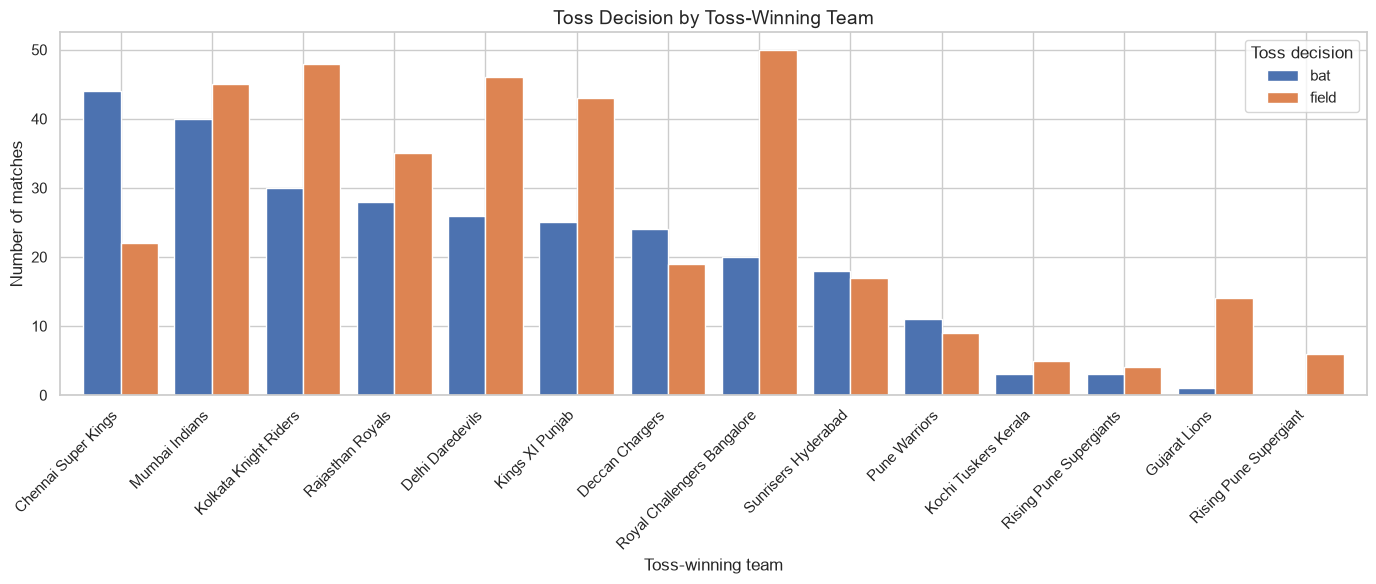

toss_decision,bat,field
toss_winner,,
Chennai Super Kings,44,22
Deccan Chargers,24,19
Delhi Daredevils,26,46
Gujarat Lions,1,14
Kings XI Punjab,25,43
Kochi Tuskers Kerala,3,5
Kolkata Knight Riders,30,48
Mumbai Indians,40,45
Pune Warriors,11,9


In [10]:
toss_table = pd.crosstab(df["toss_winner"], df["toss_decision"])
ax = toss_table.sort_values(by=list(toss_table.columns), ascending=False).plot(
    kind="bar", figsize=(14, 6), width=0.82
)
ax.set_title("Toss Decision by Toss-Winning Team")
ax.set_xlabel("Toss-winning team")
ax.set_ylabel("Number of matches")
ax.legend(title="Toss decision")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(toss_table)

## 7. Pie chart — overall toss decisions

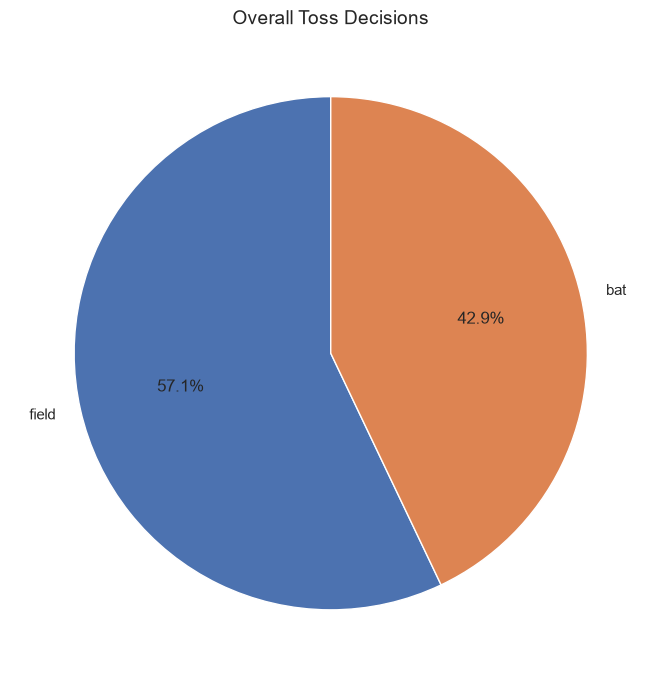

,Number of matches
toss_decision,
field,363
bat,273


In [11]:
decision_counts = df["toss_decision"].dropna().value_counts()
plt.figure(figsize=(7, 7))
plt.pie(
    decision_counts,
    labels=decision_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Overall Toss Decisions")
plt.tight_layout()
plt.show()

display(decision_counts.to_frame("Number of matches"))

## 8. Line chart — number of matches per season

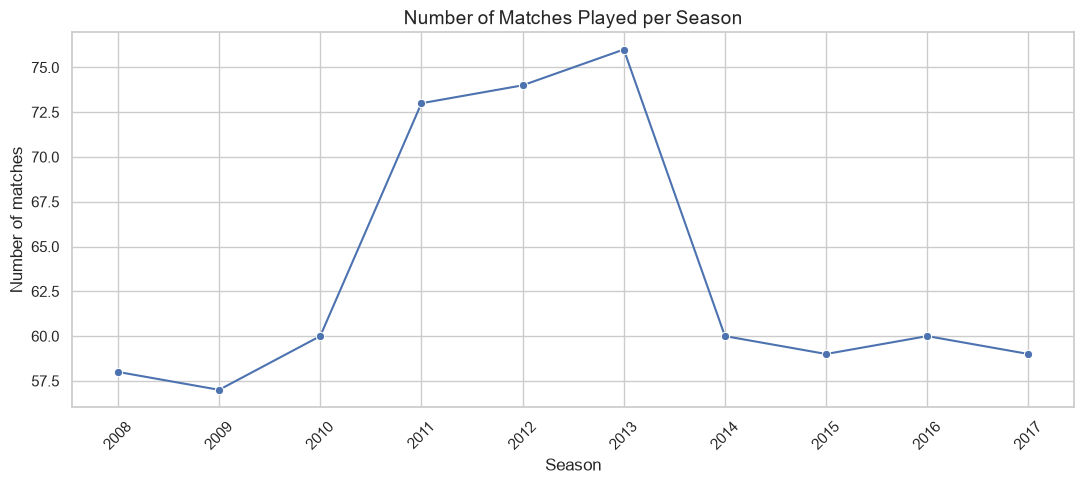

,Matches
season,
2008,58
2009,57
2010,60
2011,73
2012,74
2013,76
2014,60
2015,59
2016,60


In [12]:
matches_per_season = df.groupby("season")["id"].count().sort_index()
plt.figure(figsize=(11, 5))
sns.lineplot(x=matches_per_season.index, y=matches_per_season.values, marker="o")
plt.title("Number of Matches Played per Season")
plt.xlabel("Season")
plt.ylabel("Number of matches")
plt.xticks(matches_per_season.index, rotation=45)
plt.tight_layout()
plt.show()

display(matches_per_season.to_frame("Matches"))

## 9. Histogram — distribution of victory margin by runs

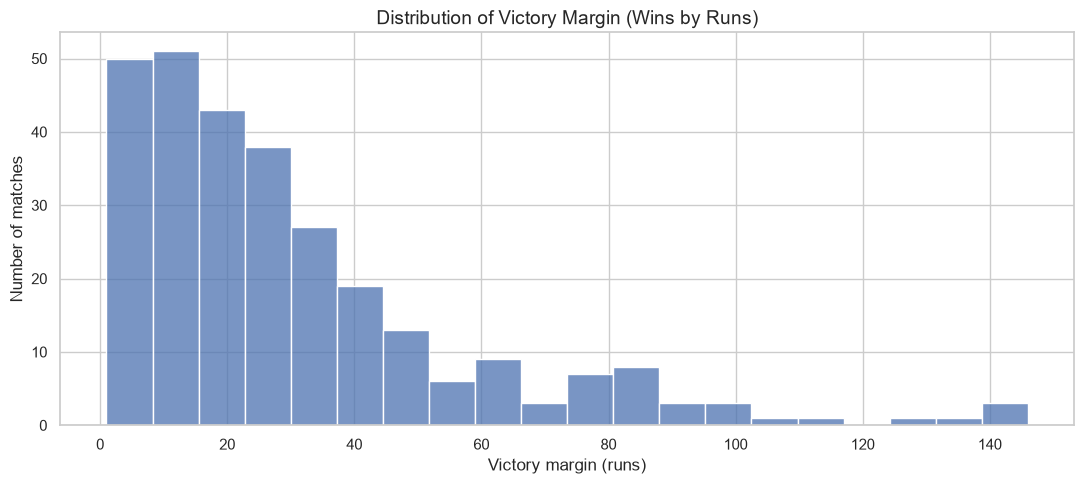

Matches decided by runs: 287


In [13]:
run_margins = df.loc[df["win_by_runs"] > 0, "win_by_runs"].dropna()
plt.figure(figsize=(11, 5))
sns.histplot(run_margins, bins=20, kde=False)
plt.title("Distribution of Victory Margin (Wins by Runs)")
plt.xlabel("Victory margin (runs)")
plt.ylabel("Number of matches")
plt.tight_layout()
plt.show()

print("Matches decided by runs:", len(run_margins))

## 10. Scatter plot — toss wins vs match wins by team

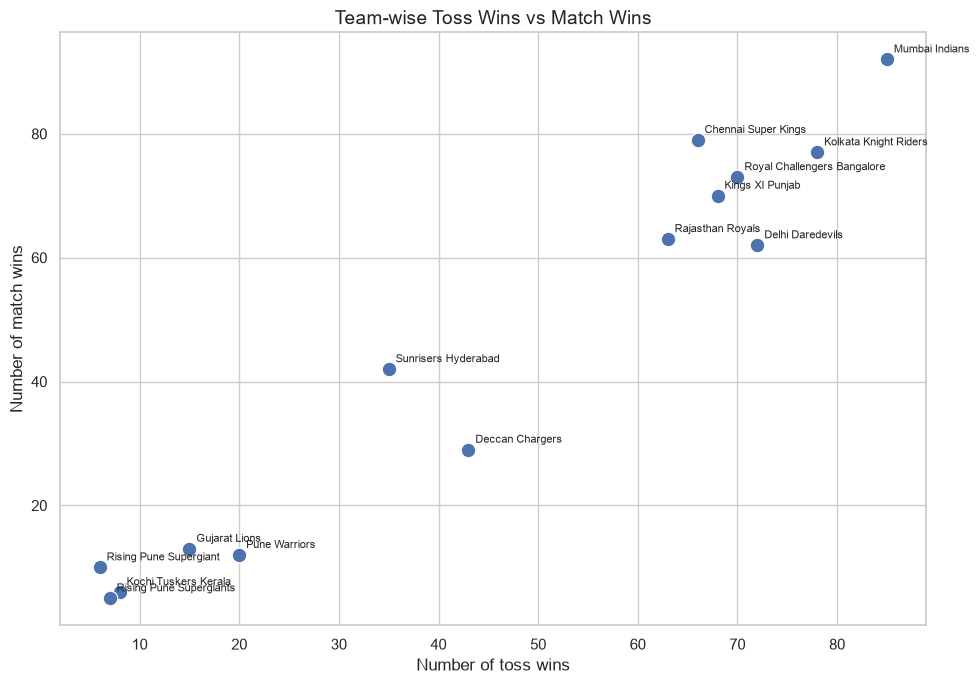

,Toss wins,Match wins
Mumbai Indians,85,92
Kolkata Knight Riders,78,77
Delhi Daredevils,72,62
Royal Challengers Bangalore,70,73
Kings XI Punjab,68,70
Chennai Super Kings,66,79
Rajasthan Royals,63,63
Deccan Chargers,43,29
Sunrisers Hyderabad,35,42
Pune Warriors,20,12


In [14]:
toss_wins = df["toss_winner"].value_counts().rename("Toss wins")
match_wins = df["winner"].value_counts().rename("Match wins")
team_summary = pd.concat([toss_wins, match_wins], axis=1).fillna(0)

plt.figure(figsize=(10, 7))
sns.scatterplot(data=team_summary, x="Toss wins", y="Match wins", s=110)
for team, row in team_summary.iterrows():
    plt.annotate(
        str(team),
        (row["Toss wins"], row["Match wins"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )
plt.title("Team-wise Toss Wins vs Match Wins")
plt.xlabel("Number of toss wins")
plt.ylabel("Number of match wins")
plt.tight_layout()
plt.show()

display(team_summary.sort_values("Toss wins", ascending=False))

## 11. Save analysis outputs

In [15]:
# Save useful summary tables and prepared dataset
toss_table.to_csv("toss_decision_by_team.csv")
team_summary.to_csv("team_toss_vs_match_wins.csv")
df.to_csv("cricket_data_prepared.csv", index=False)

print("Files saved in:", Path.cwd())
print("- toss_decision_by_team.csv")
print("- team_toss_vs_match_wins.csv")
print("- cricket_data_prepared.csv")

Files saved in: D:\OneDrive\Python_Project\Task_3_Data_Cleaning
- toss_decision_by_team.csv
- team_toss_vs_match_wins.csv
- cricket_data_prepared.csv


## 12. Key findings and conclusion

In [17]:
print("KEY FINDINGS FROM THIS DATASET")
print("-" * 40)
print("Most common toss decision:", decision_counts.idxmax(),
f"({decision_counts.max()} matches)")
print("Team with most toss wins:", toss_wins.idxmax(),
f"({toss_wins.max()} toss wins)")
print("Season with most matches:", matches_per_season.idxmax(),
f"({matches_per_season.max()} matches)")
print("Highest run victory margin:", int(run_margins.max()) if len(run_margins) else "Not available")
print("\\nUse the five charts above to explain the patterns. Remember: a relationship between toss wins and match wins does not prove that winning the toss causes a match victory.")

KEY FINDINGS FROM THIS DATASET
----------------------------------------
Most common toss decision: field (363 matches)
Team with most toss wins: Mumbai Indians (85 toss wins)
Season with most matches: 2013 (76 matches)
Highest run victory margin: 146
\nUse the five charts above to explain the patterns. Remember: a relationship between toss wins and match wins does not prove that winning the toss causes a match victory.
